### Apartment Price Prediction in Morocco

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
from pathlib import Path

# Use the local file or the dataset attached to the notebook on Kaggle.
local_csv = Path('appartements_data.csv')
kaggle_csv = Path('/kaggle/input/appartements-data/appartements_data.csv')
csv_path = local_csv if local_csv.is_file() else kaggle_csv
if not csv_path.is_file():
    raise FileNotFoundError(
        "appartements_data.csv not found. Place it in the working directory "
        "or add the appartements-data dataset on Kaggle."
    )
print(f"Data loaded from: {csv_path}")

Data loaded from: appartements_data.csv


In [3]:
import warnings
warnings.filterwarnings("ignore")


### **Importing the Data**

In [4]:
appartements_data = pd.read_csv(csv_path)
appartements_data.head()

,title,price,city_name,salon,nb_rooms,nb_baths,surface_area,equipment,link
0,CMN-MA-1752 - Appartement à vendre à Palmier,2 000 000 DH,Casablanca,NaN,2.0,2.0,168.0,Ascenseur/Balcon/Parking/Terrasse,https://www.avito.ma/fr/palmier/appartements/C...
1,66370-Vente Appt à Casablanca Hay Hassani de 1...,1 195 000 DH,Casablanca,NaN,2.0,2.0,98.0,Ascenseur/Balcon/Chauffage/Climatisation/Cuisi...,https://www.avito.ma/fr/hay_hassani/appartemen...
2,Appartement à vendre 81 m² à Dar Bouazza,1 350 000 DH,Dar Bouazza,1.0,2.0,2.0,81.0,Ascenseur/Balcon/Chauffage/Climatisation/Conci...,https://www.avito.ma/fr/dar_bouazza/appartemen...
3,63860-Vente Appt à Casablanca Quartier Bd Med ...,900 000 DH,Casablanca,NaN,1.0,1.0,56.0,Ascenseur/Chauffage/Climatisation/Cuisine Équi...,https://www.avito.ma/fr/centre_ville/apparteme...
4,Appartement à Rabat Agdal,3 100 000 DH,Rabat,2.0,3.0,2.0,200.0,Ascenseur/Balcon/Concierge/Parking/Sécurité,https://www.avito.ma/fr/agdal/appartements/App...


### Data Cleaning and Transformation

#### Converting apartment prices from object to numeric values

In [5]:
print("Before starting the analysis, convert price strings to numeric values, "
      "as price is the target variable.\n")

# Remove nonnumeric characters and convert the values to floats
'''Convert the values to strings, remove nonnumeric characters while retaining decimal points,
then convert them to numbers. Empty or invalid values become missing values.
'''
appartements_data['price'] = appartements_data['price'].astype(str).str.replace(r'[^\d.]', '', regex=True)
appartements_data['price'] = pd.to_numeric(appartements_data['price'], errors='coerce')

# Display the resulting data type
print("\n Price data type after conversion:")
print(appartements_data['price'].dtype)


Before starting the analysis, convert price strings to numeric values, as price is the target variable.


 Price data type after conversion:
float64


#### Extracting equipment as Boolean variables

In [6]:
# Get the unique equipment values in the feature
all_equipments = appartements_data['equipment'].str.split('/').explode().unique()

# Create a column for each equipment item and add it to the dataset
for equipment in all_equipments:
    equipment_str = str(equipment)
    if equipment_str: # use False for missing values
        appartements_data[equipment_str.strip()] = appartements_data['equipment'].str.contains(equipment_str, na=False)

# Drop the equipment feature and the nan column
appartements_data.drop('equipment', axis=1, inplace=True)
appartements_data.drop('nan' , axis =1 , inplace= True)
# Display the transformed dataset
appartements_data.head()

,title,price,city_name,salon,nb_rooms,nb_baths,surface_area,link,Ascenseur,Balcon,Parking,Terrasse,Chauffage,Climatisation,Cuisine Équipée,Concierge,Duplex,Sécurité,Meublé
0,CMN-MA-1752 - Appartement à vendre à Palmier,2000000.0,Casablanca,NaN,2.0,2.0,168.0,https://www.avito.ma/fr/palmier/appartements/C...,True,True,True,True,False,False,False,False,False,False,False
1,66370-Vente Appt à Casablanca Hay Hassani de 1...,1195000.0,Casablanca,NaN,2.0,2.0,98.0,https://www.avito.ma/fr/hay_hassani/appartemen...,True,True,True,False,True,True,True,False,False,False,False
2,Appartement à vendre 81 m² à Dar Bouazza,1350000.0,Dar Bouazza,1.0,2.0,2.0,81.0,https://www.avito.ma/fr/dar_bouazza/appartemen...,True,True,True,True,True,True,True,True,True,True,False
3,63860-Vente Appt à Casablanca Quartier Bd Med ...,900000.0,Casablanca,NaN,1.0,1.0,56.0,https://www.avito.ma/fr/centre_ville/apparteme...,True,False,True,True,True,True,True,False,False,True,True
4,Appartement à Rabat Agdal,3100000.0,Rabat,2.0,3.0,2.0,200.0,https://www.avito.ma/fr/agdal/appartements/App...,True,True,True,False,False,False,False,True,False,True,False


#### Standardizing city names (Arabic → French)

In [7]:
'''First list the cities in the dataset and find their French equivalents.'''
print(appartements_data['city_name'].unique())



['Casablanca' 'Dar Bouazza' 'Rabat' 'Marrakech' 'Asilah' 'Bouskoura'
 'Kénitra' 'Mohammedia' 'Agadir' 'Tamesna' 'Salé' 'Had Soualem' 'Temara'
 'Benslimane' 'Tanger' 'Bouznika' 'Meknès' 'Fès' 'El Jadida'
 'El Mansouria' 'Martil' 'الدار البيضاء' 'Fnideq' 'Tétouan' 'Saidia'
 'Nouaceur' 'القنيطرة' 'Tamaris' 'طنجة' 'Cabo Negro'
 'Sidi Allal El Bahraoui' 'Béni Mellal' 'أكادير' nan 'Essaouira' 'Mehdia'
 'المحمدية' 'Oujda' 'Oued Laou' 'Dcheira' 'Sidi Rahal' 'Deroua' 'مراكش'
 'Ain Attig' 'Safi' 'الرباط' 'Inzegan' 'Ifrane' 'Dakhla'
 'Dcheïra El Jihadia' 'Taghazout' 'Sidi Bouknadel' 'Skhirat' 'Khouribga'
 'Berkane' 'Mers El Kheir' 'Berrechid' 'Tiznit' 'Agadir Melloul' 'Nador'
 'El Menzeh' 'Bni Ansar' 'Mdiq' 'Tit Mellil' 'Souk El Arbaa' 'Biougra'
 'Settat' 'Ain Aouda' 'Taza' 'Khemisset' 'Oued Zem' 'Sefrou' 'Merzouga'
 'El Hajeb' 'Selouane' 'Taounate' 'Sidi Bennour' 'El Ksiba']


In [8]:

# Define a mapping for city names
city_mapping = {
    'الدار البيضاء': 'Casablanca',
    'الرباط': 'Rabat',
    'مراكش': 'Marrakech',
    'أكادير': 'Agadir',
    'القنيطرة' : 'Kénitra',
    'طنجة' : 'Tanger',
    'المحمدية' : 'Mohammedia'
}

# Apply the mapping to the city_name column
appartements_data['city_name'] = appartements_data['city_name'].replace(city_mapping)

# Display the result
print("Unique city names after unification:")
print(appartements_data['city_name'].unique())

Unique city names after unification:
['Casablanca' 'Dar Bouazza' 'Rabat' 'Marrakech' 'Asilah' 'Bouskoura'
 'Kénitra' 'Mohammedia' 'Agadir' 'Tamesna' 'Salé' 'Had Soualem' 'Temara'
 'Benslimane' 'Tanger' 'Bouznika' 'Meknès' 'Fès' 'El Jadida'
 'El Mansouria' 'Martil' 'Fnideq' 'Tétouan' 'Saidia' 'Nouaceur' 'Tamaris'
 'Cabo Negro' 'Sidi Allal El Bahraoui' 'Béni Mellal' nan 'Essaouira'
 'Mehdia' 'Oujda' 'Oued Laou' 'Dcheira' 'Sidi Rahal' 'Deroua' 'Ain Attig'
 'Safi' 'Inzegan' 'Ifrane' 'Dakhla' 'Dcheïra El Jihadia' 'Taghazout'
 'Sidi Bouknadel' 'Skhirat' 'Khouribga' 'Berkane' 'Mers El Kheir'
 'Berrechid' 'Tiznit' 'Agadir Melloul' 'Nador' 'El Menzeh' 'Bni Ansar'
 'Mdiq' 'Tit Mellil' 'Souk El Arbaa' 'Biougra' 'Settat' 'Ain Aouda' 'Taza'
 'Khemisset' 'Oued Zem' 'Sefrou' 'Merzouga' 'El Hajeb' 'Selouane'
 'Taounate' 'Sidi Bennour' 'El Ksiba']


In [9]:
### Inspect the dataset
# The price type has been adjusted and can be used
# in the exploratory analysis

appartements_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1773 entries, 0 to 1772
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   title            1772 non-null   object 
 1   price            1490 non-null   float64
 2   city_name        1772 non-null   object 
 3   salon            1620 non-null   float64
 4   nb_rooms         1490 non-null   float64
 5   nb_baths         1480 non-null   float64
 6   surface_area     1742 non-null   float64
 7   link             1773 non-null   object 
 8   Ascenseur        1773 non-null   bool   
 9   Balcon           1773 non-null   bool   
 10  Parking          1773 non-null   bool   
 11  Terrasse         1773 non-null   bool   
 12  Chauffage        1773 non-null   bool   
 13  Climatisation    1773 non-null   bool   
 14  Cuisine Équipée  1773 non-null   bool   
 15  Concierge        1773 non-null   bool   
 16  Duplex           1773 non-null   bool   
 17  Sécurité      

In [10]:
# Inspect summary statistics
appartements_data.describe()

,price,salon,nb_rooms,nb_baths,surface_area
count,1.490000e+03,1620.000000,1490.000000,1480.000000,1742.000000
mean,1.175197e+06,1.267284,2.379195,2.307432,174.933410
std,1.267979e+06,0.557539,0.667159,7.629128,2969.500693
min,3.500000e+01,0.000000,1.000000,0.000000,1.000000
25%,5.900000e+05,1.000000,2.000000,1.000000,71.000000
50%,8.800000e+05,1.000000,2.000000,2.000000,89.000000
75%,1.400000e+06,1.000000,3.000000,2.000000,114.750000
max,2.400000e+07,8.000000,7.000000,134.000000,123456.000000


## **Exploratory Data Analysis**

#### Univariate analysis

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'salon'}>],
       [<Axes: title={'center': 'nb_rooms'}>,
        <Axes: title={'center': 'nb_baths'}>],
       [<Axes: title={'center': 'surface_area'}>, <Axes: >]], dtype=object)

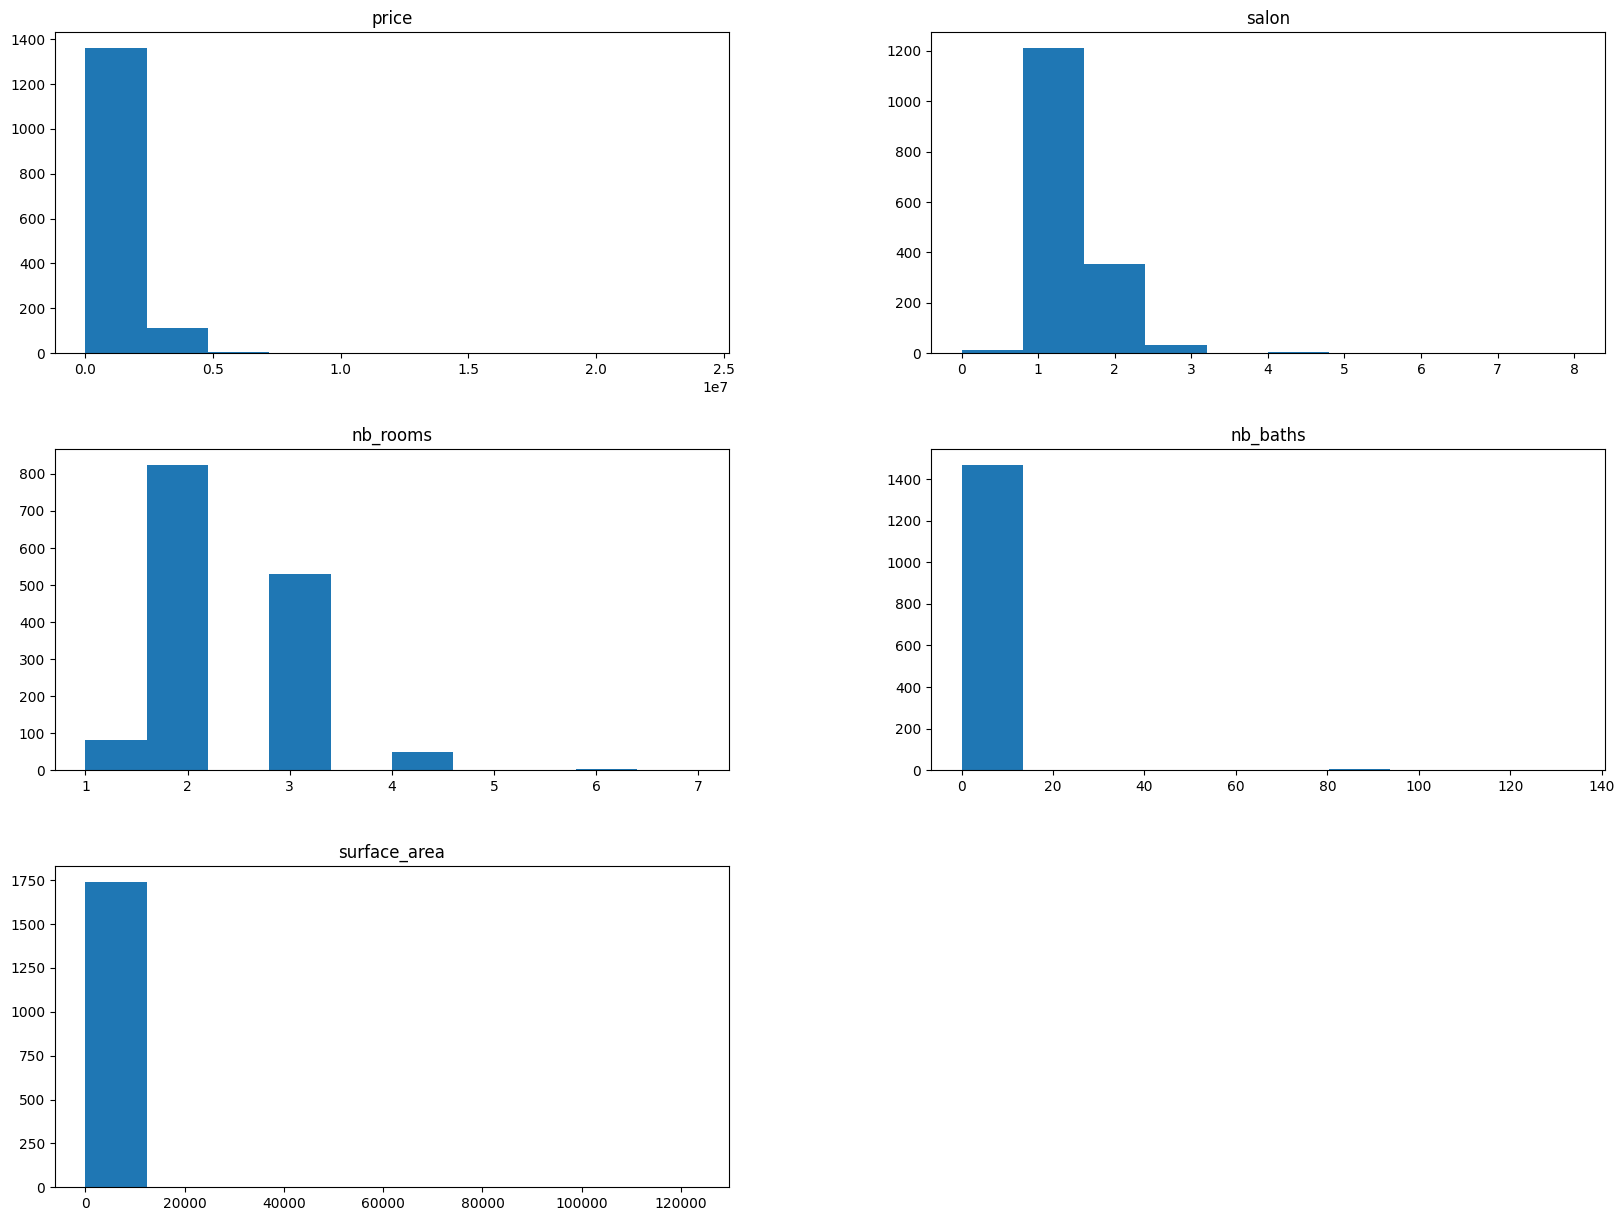

In [11]:
appartements_data.hist(figsize=(20,15),  grid = False )

'Price values are widely dispersed and include outliers, making outliers in other features difficult to see on this plot.'

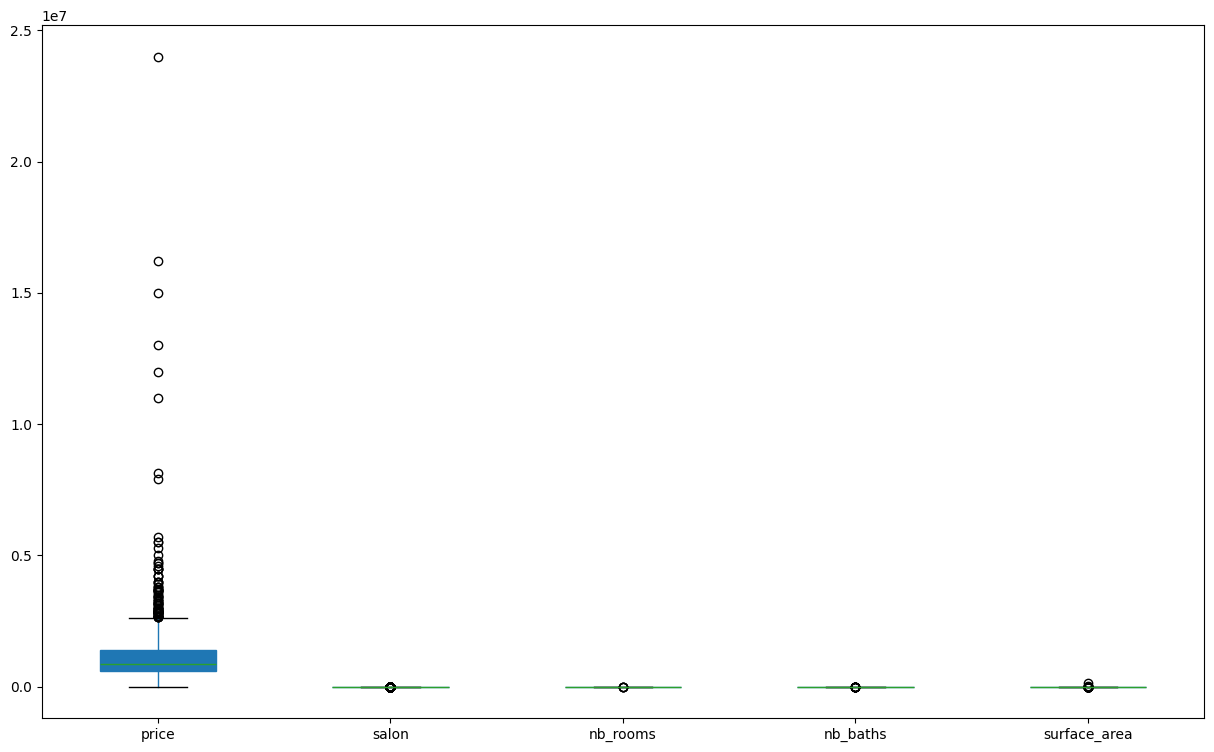

In [12]:
# Remove nan from all_equipments before dropping columns
all_equipments_filtered = [eq for eq in all_equipments if pd.notna(eq)]

appartements_data.drop(columns=all_equipments_filtered).boxplot( figsize = (15, 9),grid=False, patch_artist=True,
                    flierprops=dict(marker='o', markersize=6))

'''Price values are widely dispersed and include outliers, making outliers in other features difficult to see on this plot.'''

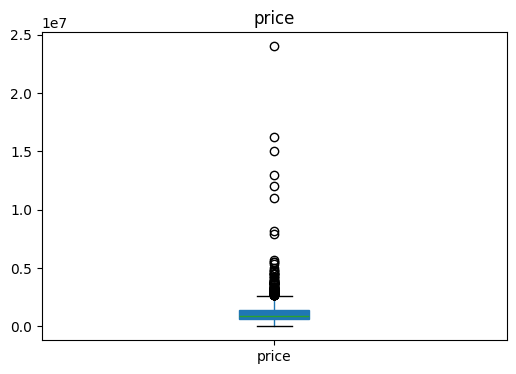

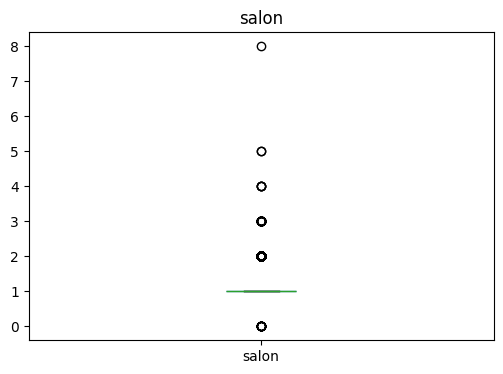

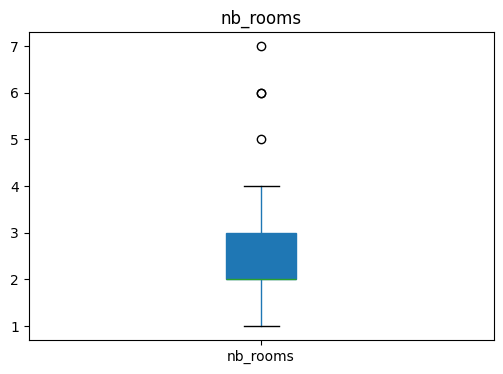

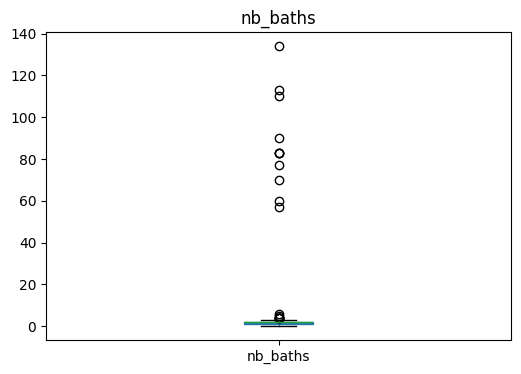

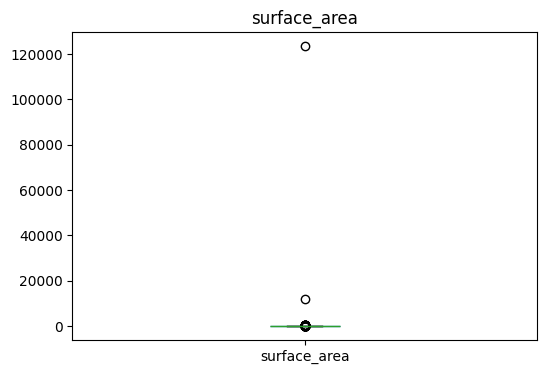

In [13]:
# Plot each numeric feature separately to inspect outliers
for col in appartements_data.select_dtypes(include = np.number).columns:
    appartements_data.boxplot(column=col, figsize=(6,4), grid=False, patch_artist=True,
                   flierprops=dict(marker='o', markersize=6))
    plt.title(col)
    plt.show()


'Reducing the spread makes the boxplots easier to interpret.'

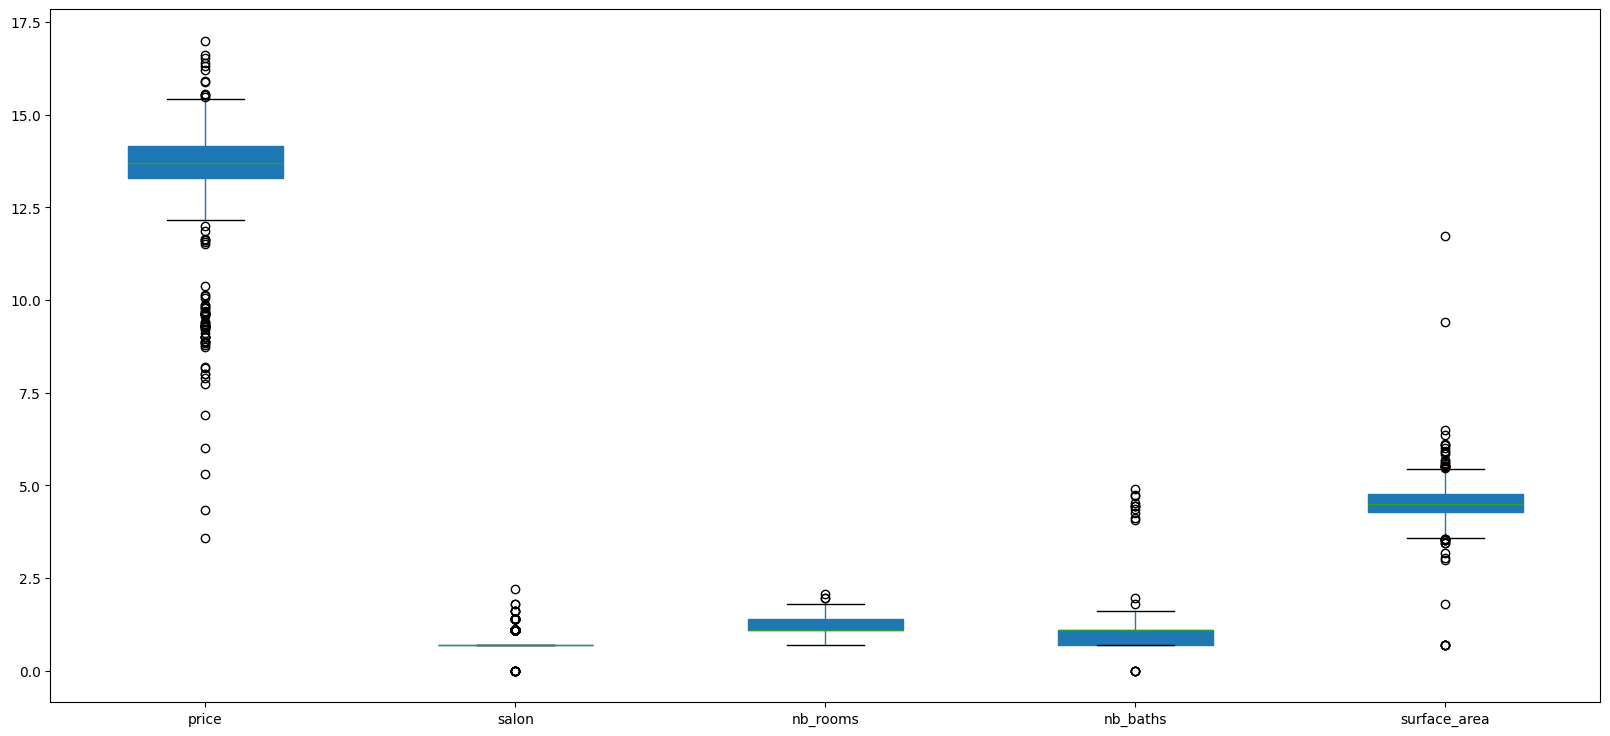

In [14]:
df_num = appartements_data.select_dtypes(include=np.number)

# Apply log(1+x) to reduce the spread
df_log = np.log1p(df_num)

df_log.boxplot(
    figsize=(20,9),
    grid=False,
    patch_artist=True,
    flierprops=dict(marker='o', markersize=6)
)

'''Reducing the spread makes the boxplots easier to interpret.'''

#### Bivariate analysis

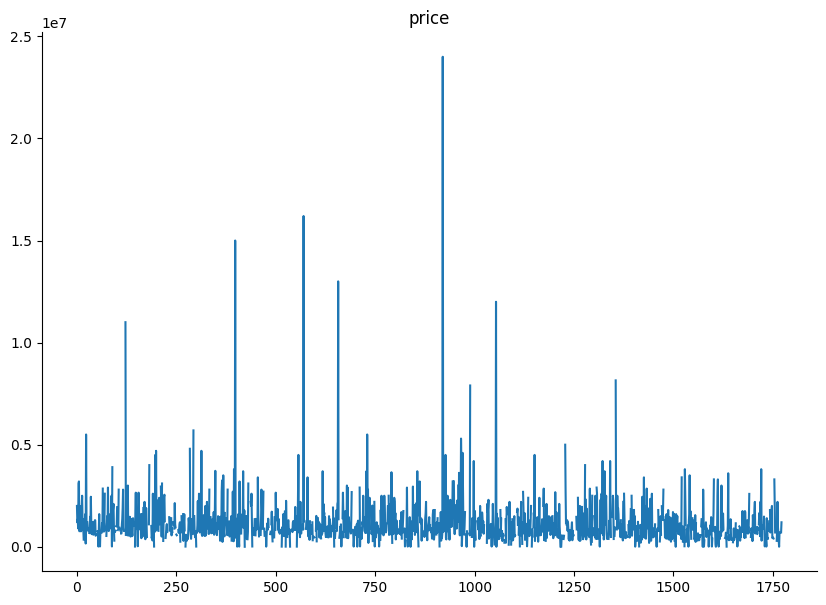

In [15]:
## Price variation
from matplotlib import pyplot as plt
appartements_data['price'].plot(kind='line', figsize=(10, 7), title='price')
plt.gca().spines[['top', 'right']].set_visible(False)

'The visualization suggests that most features have little relationship with one another.'

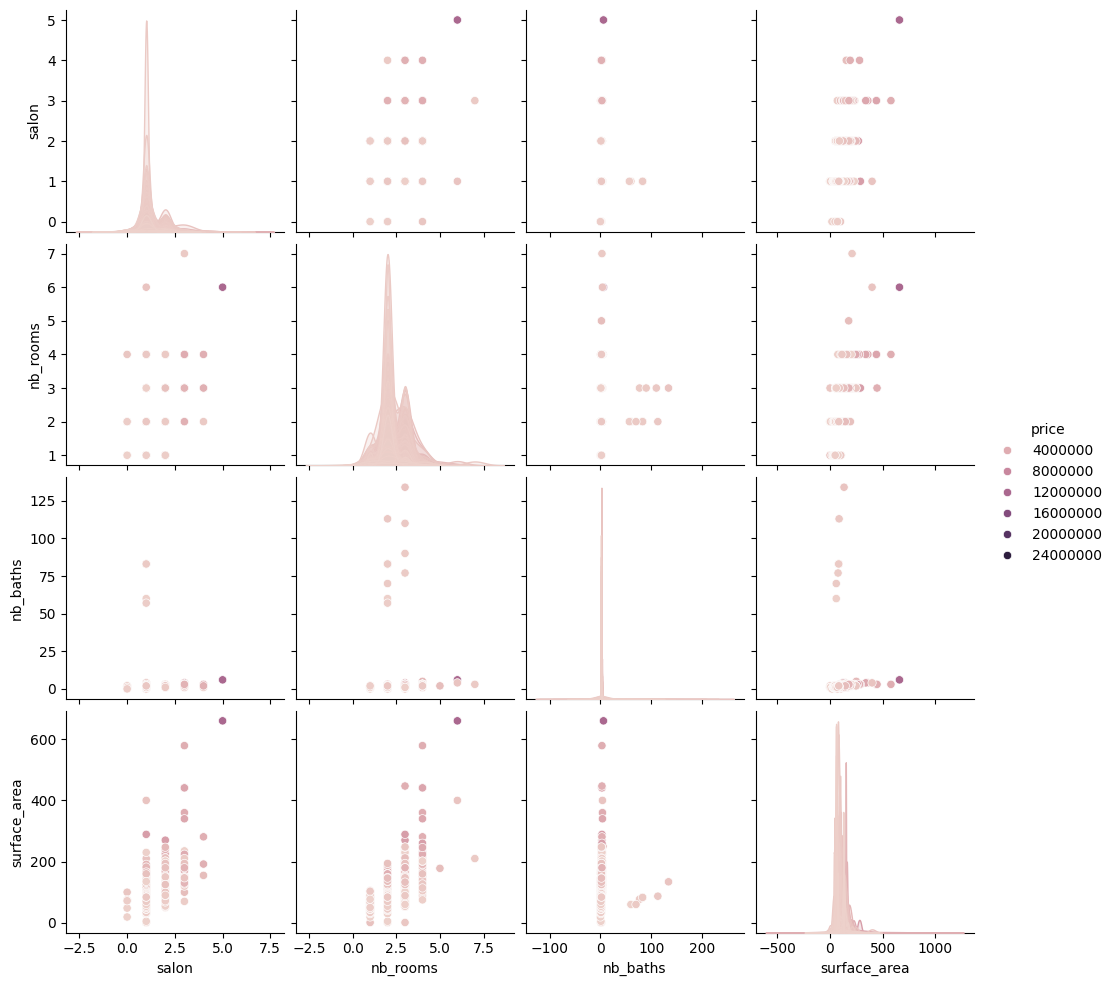

In [16]:
sns.pairplot(appartements_data.drop(columns=all_equipments_filtered) , hue = 'price')
'''The visualization suggests that most features have little relationship with one another.'''

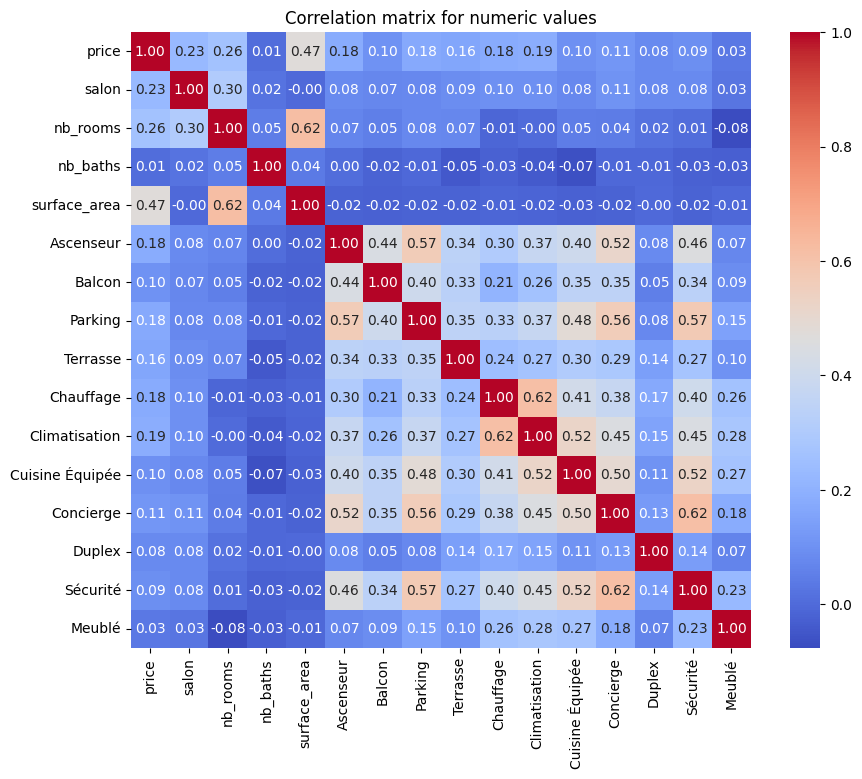

Features strongly correlated with price (>0.15):
['salon', 'nb_rooms', 'surface_area', 'Ascenseur', 'Parking', 'Terrasse', 'Chauffage', 'Climatisation']

Final nonredundant features:
['salon', 'nb_rooms', 'surface_area', 'Ascenseur', 'Parking', 'Terrasse', 'Chauffage', 'Climatisation']


In [17]:

correlation_matrix = appartements_data.select_dtypes(include=["number", "bool"]).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation matrix for numeric values')
plt.show()
'''The correlation matrix suggests that most features are not strongly correlated.
The number of rooms and surface area are correlated, while price and surface area are weakly correlated.
For this analysis, select nonredundant features with an absolute correlation above 0.15 with price.
'''

# Select features correlated with the target price

threshold = 0.15
# Exclude price itself and retain correlations above the threshold
high_corr_features = correlation_matrix['price'][correlation_matrix['price'].abs() > threshold].index.tolist()

# Remove price from the list
high_corr_features = [feat for feat in high_corr_features if feat != 'price']

print("Features strongly correlated with price (>0.15):")
print(high_corr_features)


# Create a correlation matrix for the selected features
subset_corr = correlation_matrix.loc[high_corr_features, high_corr_features].abs()

# Final list of nonredundant features
selected_features = []

for col in subset_corr.columns:
    # Check whether this column is strongly correlated with an already selected feature
    if not any(subset_corr[col][selected_features] > 0.8):
        selected_features.append(col)

print("\nFinal nonredundant features:")
print(selected_features)

In [18]:
## Collect variables not selected by correlation with price
non_selected_features = [feat for feat in appartements_data.columns if feat not in selected_features]
print(non_selected_features)

['title', 'price', 'city_name', 'nb_baths', 'link', 'Balcon', 'Cuisine Équipée', 'Concierge', 'Duplex', 'Sécurité', 'Meublé']


## Handling Outliers and Missing Values

### Missing values

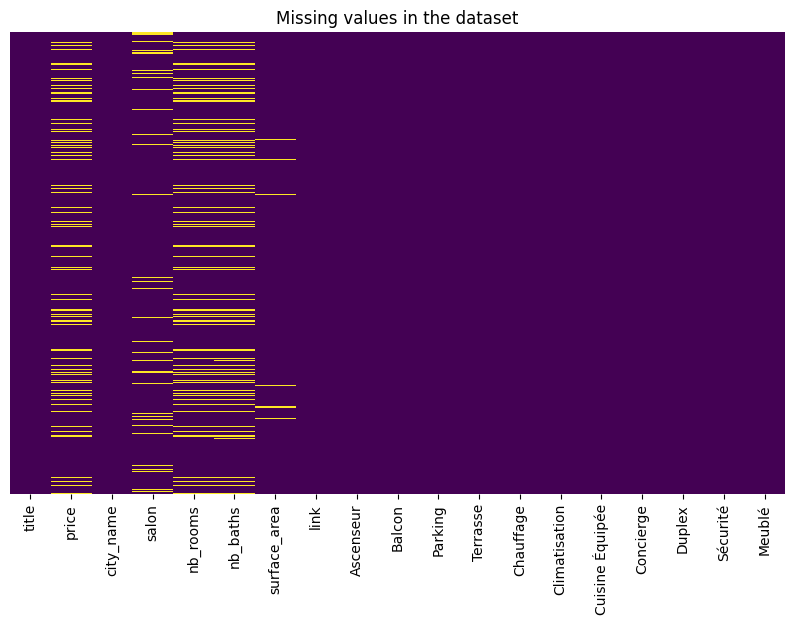

In [19]:
# Create a heatmap to detect missing feature values
plt.figure(figsize=(10,6))
sns.heatmap(appartements_data.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing values in the dataset")
plt.show()

In [20]:
appartements_data.isnull().sum()

title                1
price              283
city_name            1
salon              153
nb_rooms           283
nb_baths           293
surface_area        31
link                 0
Ascenseur            0
Balcon               0
Parking              0
Terrasse             0
Chauffage            0
Climatisation        0
Cuisine Équipée      0
Concierge            0
Duplex               0
Sécurité             0
Meublé               0
dtype: int64

In [21]:
'''Some features have missing values. Numeric values will be replaced with the median.
Categorical values such as title and city_name can be handled separately, for example with the mode or an unknown value.
'''
# Select only numerical columns
numerical_cols = appartements_data.select_dtypes(include=np.number).columns

# Fill missing values in numerical columns with the median of each column
appartements_data[numerical_cols] = appartements_data[numerical_cols].fillna(appartements_data[numerical_cols].median())

# You might want to handle missing values in non-numerical columns separately if needed.
# For example, for 'title' and 'city_name', which have only one missing value each:
appartements_data['title'].fillna('Inconnu', inplace=True)
appartements_data['city_name'].fillna('Inconnu', inplace=True)


print("\nNumber of missing values after imputation:")
print(appartements_data.isnull().sum())


Number of missing values after imputation:
title              0
price              0
city_name          0
salon              0
nb_rooms           0
nb_baths           0
surface_area       0
link               0
Ascenseur          0
Balcon             0
Parking            0
Terrasse           0
Chauffage          0
Climatisation      0
Cuisine Équipée    0
Concierge          0
Duplex             0
Sécurité           0
Meublé             0
dtype: int64


### Handling outliers


 Number of rows before removing outliers: 1773
Feature 'price' : 146 outliers detected


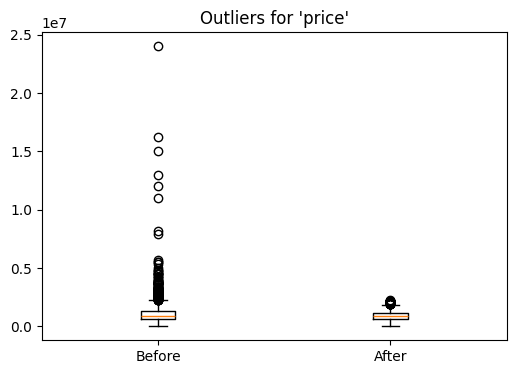

Feature 'salon' : 347 outliers detected


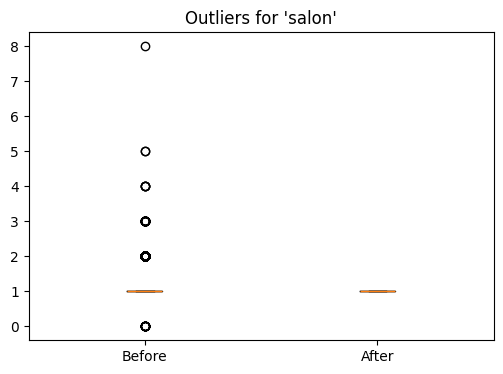

Feature 'nb_rooms' : 2 outliers detected


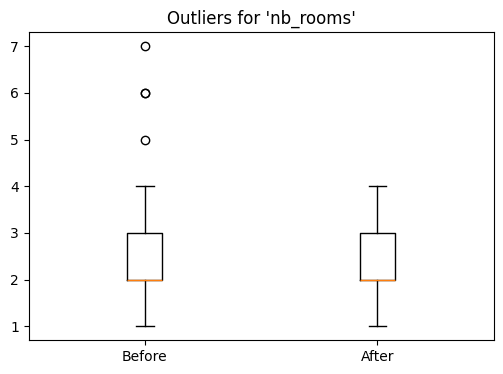

Feature 'nb_baths' : 11 outliers detected


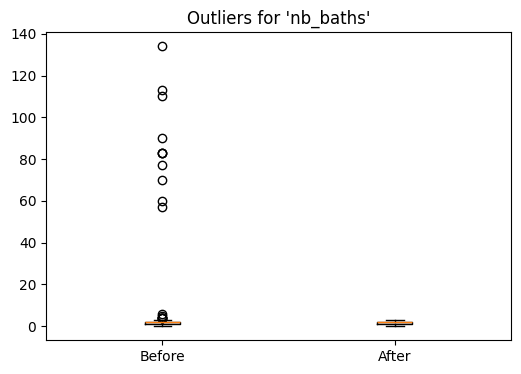

Feature 'surface_area' : 28 outliers detected


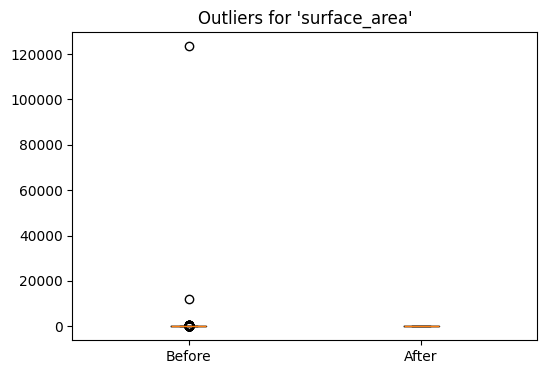


Cleaned dataset: 1239 rows remaining after outlier removal


In [22]:
'''The boxplots show outliers in the target. For apartment prices, which are often skewed and contain extreme values, the IQR approach is considered more robust than a Z-score approach.
'''
print(f"\n Number of rows before removing outliers: {appartements_data.shape[0]}")
# Keep numeric features
numerical_features = appartements_data.select_dtypes(include=np.number).columns

# Copy the dataset for cleaning
df_cleaned = appartements_data.copy()

for feature in numerical_features:
    # Calculate Q1, Q3, and IQR
    Q1 = df_cleaned[feature].quantile(0.25)
    Q3 = df_cleaned[feature].quantile(0.75)
    IQR = Q3 - Q1

    # Define the bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers before removal
    outliers_count = df_cleaned[(df_cleaned[feature] < lower_bound) | (df_cleaned[feature] > upper_bound)].shape[0]
    print(f"Feature '{feature}' : {outliers_count} outliers detected")

    # Remove detected outliers
    df_cleaned = df_cleaned[(df_cleaned[feature] >= lower_bound) & (df_cleaned[feature] <= upper_bound)]

     # Boxplot before and after
    plt.figure(figsize=(6,4))
    plt.boxplot([appartements_data[feature], df_cleaned[feature]], labels=['Before', 'After'])
    plt.title(f"Outliers for '{feature}'")
    plt.show()

print(f"\nCleaned dataset: {df_cleaned.shape[0]} rows remaining after outlier removal")



## Encoding Categorical and Boolean Variables

Encode categorical and Boolean variables so the models can interpret them.

In [23]:
# Encode Boolean values
bool_columns = appartements_data.select_dtypes(include='bool').columns.tolist()
df_cleaned[bool_columns] = df_cleaned[bool_columns].astype(int)

df_cleaned.head()

,title,price,city_name,salon,nb_rooms,nb_baths,surface_area,link,Ascenseur,Balcon,Parking,Terrasse,Chauffage,Climatisation,Cuisine Équipée,Concierge,Duplex,Sécurité,Meublé
1,66370-Vente Appt à Casablanca Hay Hassani de 1...,1195000.0,Casablanca,1.0,2.0,2.0,98.0,https://www.avito.ma/fr/hay_hassani/appartemen...,1,1,1,0,1,1,1,0,0,0,0
2,Appartement à vendre 81 m² à Dar Bouazza,1350000.0,Dar Bouazza,1.0,2.0,2.0,81.0,https://www.avito.ma/fr/dar_bouazza/appartemen...,1,1,1,1,1,1,1,1,1,1,0
3,63860-Vente Appt à Casablanca Quartier Bd Med ...,900000.0,Casablanca,1.0,1.0,1.0,56.0,https://www.avito.ma/fr/centre_ville/apparteme...,1,0,1,1,1,1,1,0,0,1,1
6,Appartement à vendre 98 m² à Marrakech,760000.0,Marrakech,1.0,3.0,3.0,98.0,https://www.avito.ma/fr/akioud/appartements/Ap...,1,1,1,0,0,0,1,1,0,1,0
7,50620-Vente Appt à Casablanca Hay Mohammadi de 73,790000.0,Casablanca,1.0,3.0,2.0,73.0,https://www.avito.ma/fr/hay_mohammadi/appartem...,0,0,0,0,0,0,1,0,0,0,0


#### Label encoding for selected machine learning models

In [24]:
from sklearn.preprocessing import LabelEncoder
'''Use label encoding for decision trees, random forests, and gradient boosting.
'''
data_label_encoding = df_cleaned.copy()
# Encode categorical variables
le = LabelEncoder()
# Apply the encoding
data_label_encoding['city_name'] = le.fit_transform(data_label_encoding['city_name'])
data_label_encoding.head()

,title,price,city_name,salon,nb_rooms,nb_baths,surface_area,link,Ascenseur,Balcon,Parking,Terrasse,Chauffage,Climatisation,Cuisine Équipée,Concierge,Duplex,Sécurité,Meublé
1,66370-Vente Appt à Casablanca Hay Hassani de 1...,1195000.0,11,1.0,2.0,2.0,98.0,https://www.avito.ma/fr/hay_hassani/appartemen...,1,1,1,0,1,1,1,0,0,0,0
2,Appartement à vendre 81 m² à Dar Bouazza,1350000.0,13,1.0,2.0,2.0,81.0,https://www.avito.ma/fr/dar_bouazza/appartemen...,1,1,1,1,1,1,1,1,1,1,0
3,63860-Vente Appt à Casablanca Quartier Bd Med ...,900000.0,11,1.0,1.0,1.0,56.0,https://www.avito.ma/fr/centre_ville/apparteme...,1,0,1,1,1,1,1,0,0,1,1
6,Appartement à vendre 98 m² à Marrakech,760000.0,30,1.0,3.0,3.0,98.0,https://www.avito.ma/fr/akioud/appartements/Ap...,1,1,1,0,0,0,1,1,0,1,0
7,50620-Vente Appt à Casablanca Hay Mohammadi de 73,790000.0,11,1.0,3.0,2.0,73.0,https://www.avito.ma/fr/hay_mohammadi/appartem...,0,0,0,0,0,0,1,0,0,0,0


#### One-hot encoding for selected machine learning models

In [25]:
# One-hot encode cities
'''This approach is suitable for linear regression, SVM, and KNN.
'''

# Standardize capitalization
data_onehot_encoding = df_cleaned.copy()
data_onehot_encoding['city_name'] = data_onehot_encoding['city_name'].str.title()

data_onehot_encoding= pd.get_dummies(data_onehot_encoding, columns=['city_name'])
data_onehot_encoding.head()

,title,price,salon,nb_rooms,nb_baths,surface_area,link,Ascenseur,Balcon,Parking,...,city_name_Skhirat,city_name_Tamaris,city_name_Tamesna,city_name_Tanger,city_name_Taounate,city_name_Taza,city_name_Temara,city_name_Tit Mellil,city_name_Tiznit,city_name_Tétouan
1,66370-Vente Appt à Casablanca Hay Hassani de 1...,1195000.0,1.0,2.0,2.0,98.0,https://www.avito.ma/fr/hay_hassani/appartemen...,1,1,1,...,False,False,False,False,False,False,False,False,False,False
2,Appartement à vendre 81 m² à Dar Bouazza,1350000.0,1.0,2.0,2.0,81.0,https://www.avito.ma/fr/dar_bouazza/appartemen...,1,1,1,...,False,False,False,False,False,False,False,False,False,False
3,63860-Vente Appt à Casablanca Quartier Bd Med ...,900000.0,1.0,1.0,1.0,56.0,https://www.avito.ma/fr/centre_ville/apparteme...,1,0,1,...,False,False,False,False,False,False,False,False,False,False
6,Appartement à vendre 98 m² à Marrakech,760000.0,1.0,3.0,3.0,98.0,https://www.avito.ma/fr/akioud/appartements/Ap...,1,1,1,...,False,False,False,False,False,False,False,False,False,False
7,50620-Vente Appt à Casablanca Hay Mohammadi de 73,790000.0,1.0,3.0,2.0,73.0,https://www.avito.ma/fr/hay_mohammadi/appartem...,0,0,0,...,False,False,False,False,False,False,False,False,False,False


### Scaling numerical values

In [26]:
from sklearn.preprocessing import StandardScaler

se = StandardScaler()
data_onehot_encoding[numerical_features] = se.fit_transform(data_onehot_encoding[numerical_features])
data_onehot_encoding.head()



,title,price,salon,nb_rooms,nb_baths,surface_area,link,Ascenseur,Balcon,Parking,...,city_name_Skhirat,city_name_Tamaris,city_name_Tamesna,city_name_Tanger,city_name_Taounate,city_name_Taza,city_name_Temara,city_name_Tit Mellil,city_name_Tiznit,city_name_Tétouan
1,66370-Vente Appt à Casablanca Hay Hassani de 1...,0.774051,0.0,-0.367749,0.769735,0.631357,https://www.avito.ma/fr/hay_hassani/appartemen...,1,1,1,...,False,False,False,False,False,False,False,False,False,False
2,Appartement à vendre 81 m² à Dar Bouazza,1.132246,0.0,-0.367749,0.769735,-0.098956,https://www.avito.ma/fr/dar_bouazza/appartemen...,1,1,1,...,False,False,False,False,False,False,False,False,False,False
3,63860-Vente Appt à Casablanca Quartier Bd Med ...,0.092323,0.0,-2.219947,-1.145328,-1.172947,https://www.avito.ma/fr/centre_ville/apparteme...,1,0,1,...,False,False,False,False,False,False,False,False,False,False
6,Appartement à vendre 98 m² à Marrakech,-0.231209,0.0,1.484449,2.684798,0.631357,https://www.avito.ma/fr/akioud/appartements/Ap...,1,1,1,...,False,False,False,False,False,False,False,False,False,False
7,50620-Vente Appt à Casablanca Hay Mohammadi de 73,-0.161880,0.0,1.484449,0.769735,-0.442633,https://www.avito.ma/fr/hay_mohammadi/appartem...,0,0,0,...,False,False,False,False,False,False,False,False,False,False


In [27]:
data_label_encoding[numerical_features] = se.fit_transform(data_label_encoding[numerical_features])
data_label_encoding.head()

,title,price,city_name,salon,nb_rooms,nb_baths,surface_area,link,Ascenseur,Balcon,Parking,Terrasse,Chauffage,Climatisation,Cuisine Équipée,Concierge,Duplex,Sécurité,Meublé
1,66370-Vente Appt à Casablanca Hay Hassani de 1...,0.774051,11,0.0,-0.367749,0.769735,0.631357,https://www.avito.ma/fr/hay_hassani/appartemen...,1,1,1,0,1,1,1,0,0,0,0
2,Appartement à vendre 81 m² à Dar Bouazza,1.132246,13,0.0,-0.367749,0.769735,-0.098956,https://www.avito.ma/fr/dar_bouazza/appartemen...,1,1,1,1,1,1,1,1,1,1,0
3,63860-Vente Appt à Casablanca Quartier Bd Med ...,0.092323,11,0.0,-2.219947,-1.145328,-1.172947,https://www.avito.ma/fr/centre_ville/apparteme...,1,0,1,1,1,1,1,0,0,1,1
6,Appartement à vendre 98 m² à Marrakech,-0.231209,30,0.0,1.484449,2.684798,0.631357,https://www.avito.ma/fr/akioud/appartements/Ap...,1,1,1,0,0,0,1,1,0,1,0
7,50620-Vente Appt à Casablanca Hay Mohammadi de 73,-0.161880,11,0.0,1.484449,0.769735,-0.442633,https://www.avito.ma/fr/hay_mohammadi/appartem...,0,0,0,0,0,0,1,0,0,0,0


## Selecting explanatory variables

In [28]:
print(selected_features)
print(non_selected_features)

['salon', 'nb_rooms', 'surface_area', 'Ascenseur', 'Parking', 'Terrasse', 'Chauffage', 'Climatisation']
['title', 'price', 'city_name', 'nb_baths', 'link', 'Balcon', 'Cuisine Équipée', 'Concierge', 'Duplex', 'Sécurité', 'Meublé']


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

'''Remove title and link, which are considered of limited value for predicting apartment prices.
'''
#data_onehot_encoding = data_onehot_encoding.drop([], axis=1)
#data_label_encoding = data_label_encoding.drop(['title', 'link'], axis=1)


'''Features with a correlation below 0.15 with the target are considered insignificant for this analysis.
'''


# Preserve the city indicator columns
non_selected_features.remove("city_name")
print(non_selected_features)
X_onehot = data_onehot_encoding.drop(non_selected_features, axis=1)
print(X_onehot.columns)

y_onehot = data_onehot_encoding['price']




### Keep only significant features
selected_features = selected_features + ['city_name']
print(selected_features)
X_label = data_label_encoding.drop(['price' , 'title', 'link'], axis=1)
X_label = X_label[selected_features]
y_label = data_label_encoding['price']





['title', 'price', 'nb_baths', 'link', 'Balcon', 'Cuisine Équipée', 'Concierge', 'Duplex', 'Sécurité', 'Meublé']
Index(['salon', 'nb_rooms', 'surface_area', 'Ascenseur', 'Parking', 'Terrasse',
       'Chauffage', 'Climatisation', 'city_name_Agadir',
       'city_name_Agadir Melloul', 'city_name_Ain Aouda',
       'city_name_Ain Attig', 'city_name_Asilah', 'city_name_Berrechid',
       'city_name_Biougra', 'city_name_Bouskoura', 'city_name_Bouznika',
       'city_name_Béni Mellal', 'city_name_Cabo Negro', 'city_name_Casablanca',
       'city_name_Dakhla', 'city_name_Dar Bouazza', 'city_name_Dcheira',
       'city_name_Dcheïra El Jihadia', 'city_name_Deroua',
       'city_name_El Jadida', 'city_name_El Mansouria', 'city_name_El Menzeh',
       'city_name_Essaouira', 'city_name_Fnideq', 'city_name_Fès',
       'city_name_Had Soualem', 'city_name_Ifrane', 'city_name_Inconnu',
       'city_name_Inzegan', 'city_name_Khemisset', 'city_name_Khouribga',
       'city_name_Kénitra', 'city_name_Ma

## Splitting the Data

In [30]:
# Split the data into training and test sets

X_train_onehot, X_test_onehot, y_train_onehot, y_test_onehot = train_test_split(X_onehot, y_onehot, test_size=0.2, random_state=42)
X_train_label, X_test_label, y_train_label, y_test_label = train_test_split(X_label, y_label, test_size=0.2, random_state=42)


## Training Machine Learning Models

## One-Hot Encoded Dataset

### KNN

One-hot encoding of cities is suitable for linear regression, SVM, and KNN.

In [31]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score , accuracy_score, classification_report
knn = KNeighborsRegressor(
    n_neighbors=6,     # number of neighbors
    weights="distance", # distance weighting
    metric="minkowski", # Minkowski distance
    p=2,                # p=2 -> Euclidean, p=1 -> Manhattan
    leaf_size=30,       # parameter for optimizing neighbor search
    n_jobs=-1           # use all CPU cores
)
knn.fit(X_train_onehot, y_train_onehot)

y_pred_onehot = knn.predict(X_test_onehot)


mse_onehot = mean_squared_error(y_test_onehot, y_pred_onehot)
r2_onehot = r2_score(y_test_onehot, y_pred_onehot)

print(f"Mean Squared Error (One-Hot Encoding): {mse_onehot:.2f}")
print(f"R-squared (One-Hot Encoding): {r2_onehot:.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_onehot, 'Predicted value': y_pred_onehot})
print(valeur_comparaison)

Mean Squared Error (One-Hot Encoding): 0.59
R-squared (One-Hot Encoding): 0.37

      Actual value  Predicted value
613      -0.254318        -0.084938
380       0.046104        -0.266685
491      -0.508521         0.190474
928      -0.993819        -0.856415
140      -0.647178        -0.486798
...            ...              ...
741      -0.554740        -0.554740
1608     -1.525335        -0.957047
255      -0.092552        -0.200011
39        0.046104        -0.496566
1071     -0.577850         0.157058

[248 rows x 2 columns]


### SVM

In [32]:
from sklearn.svm import SVR

svm = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svm.fit(X_train_onehot, y_train_onehot)

y_pred_onehot = svm.predict(X_test_onehot)

mse_onehot = mean_squared_error(y_test_onehot, y_pred_onehot)
r2_onehot = r2_score(y_test_onehot, y_pred_onehot)

print(f"Mean Squared Error (One-Hot Encoding): {mse_onehot:.2f}")
print(f"R-squared (One-Hot Encoding): {r2_onehot:.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_onehot, 'Predicted value': y_pred_onehot})
print(valeur_comparaison)


Mean Squared Error (One-Hot Encoding): 0.65
R-squared (One-Hot Encoding): 0.31

      Actual value  Predicted value
613      -0.254318        -0.229258
380       0.046104        -0.330313
491      -0.508521         0.048461
928      -0.993819        -0.976869
140      -0.647178        -0.571086
...            ...              ...
741      -0.554740        -0.454889
1608     -1.525335        -1.134729
255      -0.092552        -0.422314
39        0.046104        -0.771895
1071     -0.577850         0.311492

[248 rows x 2 columns]


#### Linear Regression

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train_onehot, y_train_onehot)

y_pred_onehot = lr.predict(X_test_onehot)

mae_label = mean_squared_error(y_test_onehot, y_pred_onehot)
mse_label = mean_squared_error(y_test_onehot, y_pred_onehot)
r2_label = r2_score(y_test_onehot, y_pred_onehot)

print(f"Mean Squared Error (Label Encoding): {mse_label:.2f}")
print(f"R-squared (Label Encoding): {r2_label:.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_onehot, 'Predicted value': y_pred_onehot})
print(valeur_comparaison)


Mean Squared Error (Label Encoding): 0.75
R-squared (Label Encoding): 0.20

      Actual value  Predicted value
613      -0.254318        -0.614489
380       0.046104        -0.417038
491      -0.508521        -0.032946
928      -0.993819        -0.616252
140      -0.647178        -0.390600
...            ...              ...
741      -0.554740        -0.393370
1608     -1.525335        -1.501815
255      -0.092552        -0.125106
39        0.046104        -0.820387
1071     -0.577850         0.148271

[248 rows x 2 columns]


In [34]:
from sklearn.linear_model import  Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Models to test
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5)
}

# Store the results
results = []

# Iterate over the models
for name, model in models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        (name, model)
    ])

    # Training
    pipe.fit(X_train_onehot, y_train_onehot)

    # Predictions
    y_pred = pipe.predict(X_test_onehot)

    # Metrics
    mae = mean_absolute_error(y_test_onehot, y_pred)
    mse = mean_squared_error(y_test_onehot, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_onehot, y_pred)

    results.append([name, mae, rmse, r2])

# Results in a DataFrame
results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R²"])
print(results_df)

               Model       MAE      RMSE        R²
0  Linear Regression  0.600858  0.866429  0.199469
1              Ridge  0.600779  0.866232  0.199833
2              Lasso  0.592738  0.858300  0.214419
3         ElasticNet  0.595762  0.860484  0.210416


## Label Encoded Dataset

### KNN

In [35]:
knn = KNeighborsRegressor(
    n_neighbors=6,     # number of neighbors
    weights="distance", # distance weighting
    metric="minkowski", # Minkowski distance
    p=2,                # p=2 -> Euclidean, p=1 -> Manhattan
    leaf_size=30,       # parameter for optimizing neighbor search
    n_jobs=-1           # use all CPU cores
)
knn.fit(X_train_label, y_train_label)

y_pred_label = knn.predict(X_test_label)


mse_label = mean_squared_error(y_test_label, y_pred_label)
r2_label = r2_score(y_test_label, y_pred_label)

print(f"Mean Squared Error (Label Encoding): {mse_label:.2f}")
print(f"R-squared (Label Encoding): {r2_label:.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_label, 'Predicted value': y_pred_label})
print(valeur_comparaison)

Mean Squared Error (Label Encoding): 0.59
R-squared (Label Encoding): 0.37

      Actual value  Predicted value
613      -0.254318        -0.084938
380       0.046104        -0.266685
491      -0.508521         0.458591
928      -0.993819        -0.231879
140      -0.647178        -0.486798
...            ...              ...
741      -0.554740        -0.554740
1608     -1.525335         0.017282
255      -0.092552        -0.200011
39        0.046104        -0.496566
1071     -0.577850         0.457677

[248 rows x 2 columns]


### SVM

In [36]:
svm = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svm.fit(X_train_label, y_train_label)

y_pred_label = svm.predict(X_test_label)

mse_onehot = mean_squared_error(y_test_label, y_pred_label)
r2_onehot = r2_score(y_test_label, y_pred_label)

print(f"Mean Squared Error (One-Hot Encoding): {mse_label:.2f}")
print(f"R-squared (One-Hot Encoding): {r2_label:.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_label, 'Predicted value': y_pred_label})
print(valeur_comparaison)


Mean Squared Error (One-Hot Encoding): 0.59
R-squared (One-Hot Encoding): 0.37

      Actual value  Predicted value
613      -0.254318        -0.405024
380       0.046104        -0.168830
491      -0.508521         0.096654
928      -0.993819        -0.469542
140      -0.647178        -0.146665
...            ...              ...
741      -0.554740         0.379137
1608     -1.525335        -0.367094
255      -0.092552        -0.100767
39        0.046104        -0.278866
1071     -0.577850         0.220187

[248 rows x 2 columns]


### Random Forest

In [37]:
from sklearn.ensemble import RandomForestRegressor

rd = RandomForestRegressor(n_estimators=100, random_state=42 ,max_depth =10)
rd.fit(X_train_label, y_train_label)

y_pred_label = rd.predict(X_test_label)

mse_label = mean_squared_error(y_test_label, y_pred_label)
r2_label = r2_score(y_test_label, y_pred_label)

print(f"Mean Squared Error (Label Encoding): {mse_label:.2f}")
print(f"R-squared (Label Encoding): {r2_label:.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_label, 'Predicted value': y_pred_label})
print(valeur_comparaison)


Mean Squared Error (Label Encoding): 0.65
R-squared (Label Encoding): 0.31

      Actual value  Predicted value
613      -0.254318        -0.158734
380       0.046104        -0.235806
491      -0.508521         0.481426
928      -0.993819        -0.867180
140      -0.647178        -0.210382
...            ...              ...
741      -0.554740        -0.411028
1608     -1.525335        -0.821664
255      -0.092552        -0.227226
39        0.046104        -0.617858
1071     -0.577850         0.970041

[248 rows x 2 columns]


### Gradient Boosting

In [38]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42 , max_depth=3)


gb.fit(X_train_label, y_train_label)
y_pred_label = gb.predict(X_test_label)

mse_label = mean_squared_error(y_test_label, y_pred_label)
r2_label = r2_score(y_test_label, y_pred_label)

print(f"Mean Squared Error (Label Encoding): {mse_label :.2f}")
print(f"R-squared (Label Encoding): {r2_label :.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_label, 'Predicted value': y_pred_label})
print(valeur_comparaison)


Mean Squared Error (Label Encoding): 0.61
R-squared (Label Encoding): 0.35

      Actual value  Predicted value
613      -0.254318        -0.197187
380       0.046104        -0.440395
491      -0.508521         0.074494
928      -0.993819        -0.489600
140      -0.647178        -0.276833
...            ...              ...
741      -0.554740        -0.385406
1608     -1.525335        -1.147958
255      -0.092552        -0.153263
39        0.046104        -1.278118
1071     -0.577850         0.317512

[248 rows x 2 columns]


### Neural Network (MLP Regressor)

In [39]:
! pip install tensorflow

In [40]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LeakyReLU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dropout

model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(X_train_label.shape[1],)))
model.add(LeakyReLU(alpha=0.1))
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='linear'))


optimizer = Adam(learning_rate=0.001)
model.compile(optimizer = optimizer , loss='mean_squared_error')

# early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model.fit(X_train_label, y_train_label, epochs=100, validation_split=0.2,
          #callbacks=[early_stop],
          batch_size=32, verbose=1)

y_pred_label = model.predict(X_test_label)

mse_label = mean_squared_error(y_test_label, y_pred_label)
r2_label = r2_score(y_test_label, y_pred_label)

print(f"Mean Squared Error (Label Encoding): {mse_label:.2f}")
print(f"R-squared (Label Encoding): {r2_label:.2f}\n")

valeur_comparaison = pd.DataFrame({'Actual value': y_test_label, 'Predicted value': y_pred_label.flatten()})
print(valeur_comparaison)

I0000 00:00:1795554758.117051   78408 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795554758.220850   78408 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795554761.089374   78408 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Epoch 1/100


E0000 00:00:1795554761.366777   78408 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 6.1841 - val_loss: 1.5274
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2.4597 - val_loss: 1.1219
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.8004 - val_loss: 1.1170
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.4943 - val_loss: 1.0889
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.3114 - val_loss: 1.0937
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.1923 - val_loss: 1.0521
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.1821 - val_loss: 1.0412
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.1015 - val_loss: 1.0392
Epoch 9/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0976 - val_loss: 1.0286
Epoch 10/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0865 - val_loss: 1.0206
Epoch 11/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9992 - val_loss: 1.0078
Epoch 12/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0469 - val_l

### Regression Model Summary

Based on the R² scores obtained after training several models with one-hot and label encoding, the recorded results are:

* **KNN**: one-hot R² = 0.36; label encoding R² = 0.37
* **SVM**: one-hot R² = 0.31; label encoding R² = 0.37
* **Linear models** (Linear Regression, Ridge, Lasso, ElasticNet), with one-hot encoding: R² ≈ 0.20–0.21
* **Random Forest**, with label encoding: R² = 0.31
* **Gradient Boosting**, with label encoding: R² = 0.35
* **Neural network**, with label encoding: R² = 0.23

**Most suitable model among those tested**

Based on R², which measures the proportion of price variance explained by the model, **KNN** and **SVM** perform best, with an R² of approximately **0.37** when `city_name` is label encoded.

This suggests these models are the most suitable for predicting apartment prices *at this stage of the analysis*. However, an R² of 0.37 means that only about 37% of the variance in prices is explained, leaving considerable room for improvement.

**Potential improvements**

* Tune the hyperparameters of KNN and SVM.
* Explore more advanced models, such as XGBoost or LightGBM.
* Analyze the features in more depth and engineer more relevant features.
* Refine the handling of missing values and outliers.

## Project Summary and Conclusion

### Summary

This project explored apartment data from Morocco and prepared it for modeling. The main steps were:

- Importing and inspecting the dataset.
- Converting the price column to numeric values.
- Extracting and encoding equipment as Boolean variables.
- Standardizing city names.
- Handling missing values through mode imputation.
- Identifying and handling outliers in numeric features, especially price and surface area.
- Selecting the features most correlated with price.
- Encoding categorical variables (cities) using label encoding and one-hot encoding.
- Scaling numeric features.
- Splitting the data into training and test sets.
- Training several regression models (KNN, SVM, Linear Regression, Ridge, Lasso, ElasticNet, Random Forest, Gradient Boosting, and a simple neural network) on differently encoded datasets.

Model performance was evaluated using mean squared error (MSE) and R-squared (R²). The results obtained so far vary by model and categorical encoding method.

### Conclusion

The initial analysis and modeling provided insights into factors influencing apartment prices in Morocco. Although some models showed moderate predictive ability (R² around 0.30–0.38 for the best models tested), there is significant room for improvement. The low R² values suggest that the current models explain only part of the variance in apartment prices.

Outliers, the data distribution even after transformation, and the inherent complexity of the real estate market may be limiting factors. Handling missing values with the mode, while simple, may not be optimal for every feature.

### Possible Improvements

1. **Advanced missing-value handling:** Experiment with other imputation techniques, such as model-based or multivariate imputation, or investigate why values are missing.
2. **Deeper outlier analysis and handling:** Investigate remaining outliers and consider more robust or feature-specific detection and treatment methods.
3. **More extensive feature engineering:** Create relevant features, for example by extracting neighborhood information from listing titles or combining existing features such as surface area per room.
4. **Explore other models:** Test other regression algorithms, such as XGBoost, LightGBM, or more sophisticated tree-based models.
5. **Advanced hyperparameter tuning:** Use grid search, random search, or Bayesian optimization to find better settings for selected models.
6. **Robust cross-validation:** Use more advanced cross-validation schemes, such as stratified K-fold if prices can be grouped into bins, for a more reliable evaluation.
7. **Collect additional data:** If possible, enrich the dataset with other sources, such as socioeconomic information by city or neighborhood, nearby amenities, and construction date.
8. **Model error analysis:** Examine predictions with the largest errors to identify patterns and potentially problematic or missing features.